# Choose-r pilot: what the edit-size results show

The choose-r stage ran 50 held-out episodes, 3 SAEs (L1, Pretrained, Fine-tuned decoder) x 3 arms
(decrease, increase, both) x 4 edit sizes r, with 1 targeted edit + 3 matched random edits per condition.
The edit is applied at layer 25, at the final prompt token only.

This notebook rebuilds every row's Claude label **from the cached responses** (no API calls) and plots:

1. **Effect**: targeted minus random flip rate, with the report's 95% CIs.
2. **Flip rates themselves**: targeted vs random, per SAE and arm.
3. **Does the edit move the model at all?** How often the answer text changes, targeted vs random.
4. **Where flips come from**: which episodes flip, and how concentrated that is.
5. **Why the effect is small**: baseline confidence vs how often an episode's answer moves.
6. **Feature activity**: how many targeted features are active at the edited token.
7. **Answer quality**: % out answers by r.

Run from anywhere inside the repo with the `capstone` kernel.

In [1]:
import json, os
from pathlib import Path

# Find the repo root so the notebook works from notebooks/intervention/.
ROOT = Path.cwd()
while not (ROOT / "configs" / "intervention").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("Run this notebook from inside the repository.")
    ROOT = ROOT.parent
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from mas_sae.intervention.experiment.config import load_config
from mas_sae.intervention.experiment.episodes import study_and_choose_r_episodes
from mas_sae.intervention.analysis.labeling import label_rows, read_protocol
from mas_sae.intervention.analysis.choose_r import is_degenerate, OPPOSITE
from mas_sae.intervention.run_files.results_file import read_rows

CONFIG = Path("configs/intervention/intervention.yaml")
CHOOSE_R = Path("results/intervention_layer25/choose_r")

## Load rows and labels

`label_rows` is the same function the pipeline uses. Every answer was already labeled during choose-r,
so it reads the cache; the client factory raises if it would ever need to call Claude.

In [2]:
config = load_config(CONFIG)
_, choose_r_episodes = study_and_choose_r_episodes(config)
episodes = {e.episode_id: e for e in choose_r_episodes}
rows = read_rows(CHOOSE_R / "rows.jsonl")

def no_api_calls():
    raise RuntimeError("A label is missing from the cache: this notebook never calls Claude.")

labeled, excluded = label_rows(rows, episodes, read_protocol(Path(config.inputs.stored_labels)),
                               CHOOSE_R / "labeling", no_api_calls, concurrency=1)

df = pd.DataFrame(labeled)
base = df[df.kind == "baseline"].set_index("episode_id")
df["flip"] = (df.label == df.stored_label.map(OPPOSITE)).astype(float)
df["out"] = (df.label == "out").astype(float)
df["degenerate"] = df.apply(is_degenerate, axis=1).astype(float)
df["answer_changed"] = (df.answer.str.strip() != df.episode_id.map(base.answer.str.strip())).astype(float)
df["baseline_first_token_prob"] = np.exp(df.episode_id.map(base.first_token_logprob))
edits = df[df.kind == "edit"].copy()
edits["source"] = np.where(edits.source == "targeted", "targeted", "random")

report = pd.read_csv(CHOOSE_R / "choose_r_report.csv")
ci = report["Δ 95% CI"].str.strip("[]").str.split(",", expand=True).astype(float)
report["ci_lo"], report["ci_hi"] = ci[0], ci[1]

print(f"{len(df)} rows, {df.episode_id.nunique()} episodes, {len(excluded)} excluded for labeling failures")
print(f"baseline flip rate: {df[df.kind == 'baseline'].flip.mean():.1%}")
edits.groupby(["representation", "source"]).size().unstack()

7250 rows, 50 episodes, 0 excluded for labeling failures
baseline flip rate: 0.0%


source,random,targeted
representation,,
Fine-tuned decoder,1800,600
L1 SAE,1800,600
Pretrained SAE,1800,600


In [3]:
# Shared styling: three SAEs take the first three categorical slots (validated all-pairs);
# the random control is neutral gray so it reads as "the comparison", not a fourth series.
REPS = ["L1 SAE", "Pretrained SAE", "Fine-tuned decoder"]
ARMS = ["decrease", "increase", "both"]
SIZES = sorted(edits.edit_size.unique())
COLOR = {"L1 SAE": "#2a78d6", "Pretrained SAE": "#eb6834", "Fine-tuned decoder": "#1baf7a"}
RANDOM_GRAY = "#898781"
INK, INK_2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.labelsize": 10, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.grid.axis": "y",
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2, "lines.markersize": 7,
    "font.size": 10,
})

def size_axis(ax):
    ax.set_xticks(range(len(SIZES)), [f"{s:g}" for s in SIZES])
    ax.set_xlim(-0.4, len(SIZES) - 0.6)
    ax.set_xlabel("edit size r  (|Δ| = r·|x|)")

def pct_axis(ax):
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))

## 1. The effect: targeted minus random flip rate

This is the quantity the study tests. Each point is Δ = targeted flip % − mean random flip %, with the
report's 95% bootstrap CI over episodes. **A real effect would sit above the zero line and grow with r.**
The highlighted point is the only one that meets the report's suggested rule.

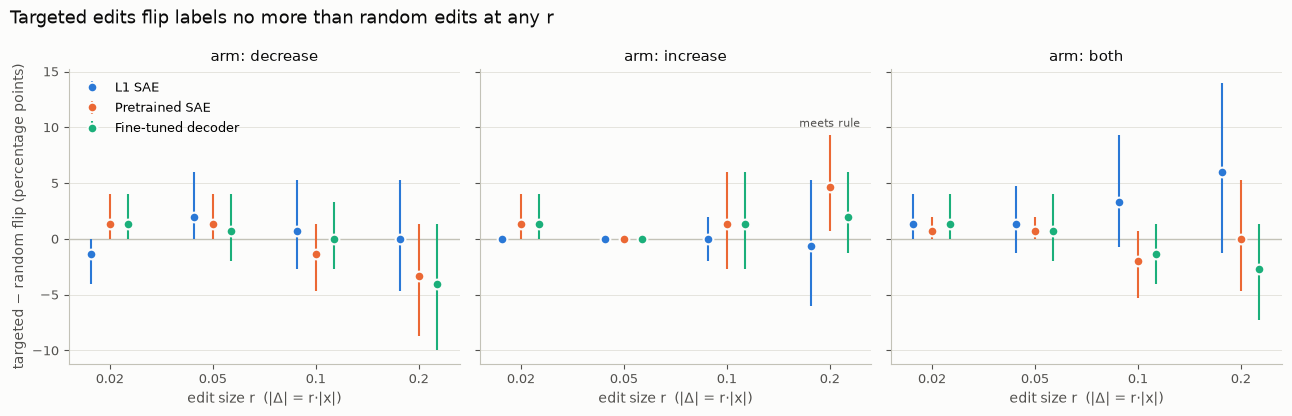

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
dodge = {"L1 SAE": -0.18, "Pretrained SAE": 0.0, "Fine-tuned decoder": 0.18}
for ax, arm in zip(axes, ARMS):
    ax.axhline(0, color=AXIS, linewidth=1, zorder=1)
    for rep in REPS:
        sub = report[(report.Representation == rep) & (report.Arm == arm)].sort_values("Edit size r")
        x = np.arange(len(sub)) + dodge[rep]
        ax.errorbar(x, sub["Δ (pp)"], yerr=[sub["Δ (pp)"] - sub.ci_lo, sub.ci_hi - sub["Δ (pp)"]],
                    fmt="o", color=COLOR[rep], ecolor=COLOR[rep], elinewidth=1.5, capsize=0,
                    markeredgecolor="#fcfcfb", markeredgewidth=1.5, label=rep, zorder=3)
        passed = sub[sub["Meets suggested rule"]]
        for i in np.flatnonzero(sub["Meets suggested rule"].to_numpy()):
            ax.annotate("meets rule", (x[i], sub.ci_hi.iloc[i]), xytext=(0, 6), textcoords="offset points",
                        ha="center", fontsize=8, color=INK_2)
    size_axis(ax)
    ax.set_title(f"arm: {arm}")
axes[0].set_ylabel("targeted − random flip (percentage points)")
axes[0].legend(loc="upper left")
fig.suptitle("Targeted edits flip labels no more than random edits at any r", x=0.01, ha="left",
             fontsize=13, color=INK)
fig.tight_layout()
plt.show()

## 2. Flip rates: targeted vs random

The same data before subtracting. Random flips (gray) are the floor any targeted effect has to beat.
Both rise with r, which says the edit size matters but the *direction* (targeted features) doesn't yet.

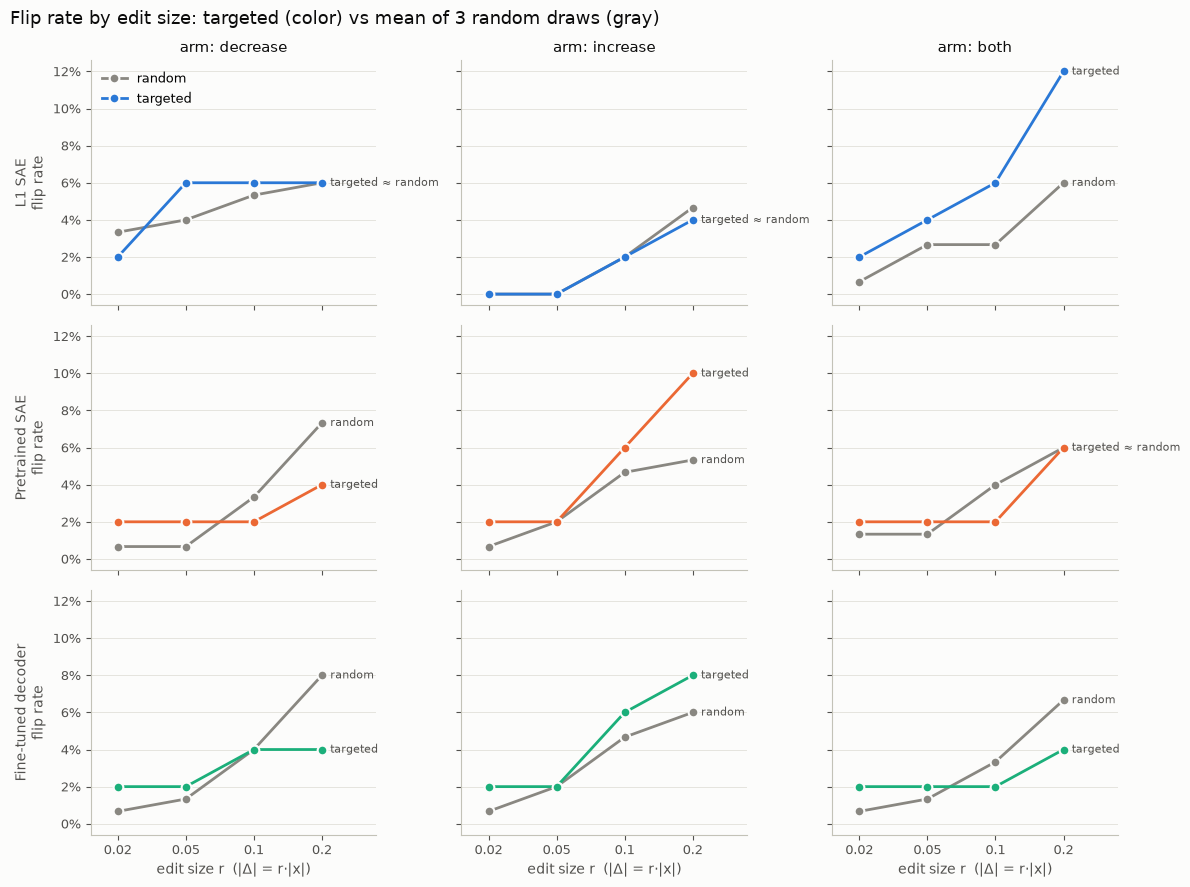

In [5]:
flip = (edits.groupby(["representation", "arm", "source", "edit_size"]).flip.mean() * 100).rename("pct").reset_index()
fig, axes = plt.subplots(3, 3, figsize=(12, 9), sharex=True, sharey=True)
for i, rep in enumerate(REPS):
    for j, arm in enumerate(ARMS):
        ax = axes[i, j]
        ends = {}
        for source, color in [("random", RANDOM_GRAY), ("targeted", COLOR[rep])]:
            s = flip[(flip.representation == rep) & (flip.arm == arm) & (flip.source == source)].sort_values("edit_size")
            ax.plot(range(len(s)), s.pct, "-o", color=color, markeredgecolor="#fcfcfb", markeredgewidth=1.5,
                    label=source, zorder=3 if source == "targeted" else 2)
            ends[source] = s.pct.iloc[-1]
        same = abs(ends["targeted"] - ends["random"]) < 0.8      # labels would collide: name both once
        for source, y in ends.items():
            if same and source == "random":
                continue
            ax.annotate("targeted ≈ random" if same else source, (len(SIZES) - 1, y), xytext=(6, 0),
                        textcoords="offset points", va="center", fontsize=8, color=INK_2)
        size_axis(ax)
        pct_axis(ax)
        if i < 2: ax.set_xlabel("")
        if i == 0: ax.set_title(f"arm: {arm}")
        if j == 0: ax.set_ylabel(f"{rep}\nflip rate")
        ax.set_xlim(-0.4, len(SIZES) - 0.2)
axes[0, 0].legend(loc="upper left")
fig.suptitle("Flip rate by edit size: targeted (color) vs mean of 3 random draws (gray)", x=0.01, ha="left",
             fontsize=13, color=INK)
fig.tight_layout()
plt.show()

## 3. Does the edit change the answer at all?

A flip needs the answer to change first, so this is the upstream check: the share of edited generations
whose answer text differs from the baseline at all, whatever the label. If targeted edits were special,
they'd change answers more often than random edits of the same size.

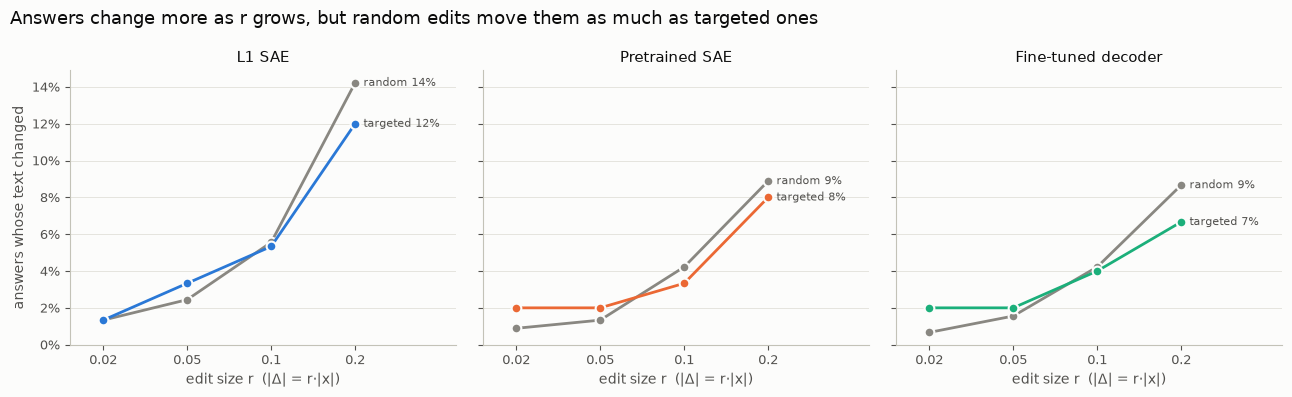

In [6]:
chg = (edits.groupby(["representation", "source", "edit_size"]).answer_changed.mean() * 100).rename("pct").reset_index()
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, rep in zip(axes, REPS):
    for source, color in [("random", RANDOM_GRAY), ("targeted", COLOR[rep])]:
        s = chg[(chg.representation == rep) & (chg.source == source)].sort_values("edit_size")
        ax.plot(range(len(s)), s.pct, "-o", color=color, markeredgecolor="#fcfcfb", markeredgewidth=1.5,
                zorder=3 if source == "targeted" else 2)
        ax.annotate(f"{source} {s.pct.iloc[-1]:.0f}%", (len(s) - 1, s.pct.iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=8, color=INK_2)
    size_axis(ax)
    ax.set_xlim(-0.4, len(SIZES) + 0.2)
    pct_axis(ax)
    ax.set_title(rep)
axes[0].set_ylabel("answers whose text changed")
fig.suptitle("Answers change more as r grows, but random edits move them as much as targeted ones",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout()
plt.show()

## 4. Where the flips come from

Each row is an episode that flipped in at least one edited generation; each cell is the share of that
episode's edited generations (all SAEs and arms) that flipped. If a few rows carry almost everything,
the pilot's flip rates are really a statement about a handful of unstable episodes.

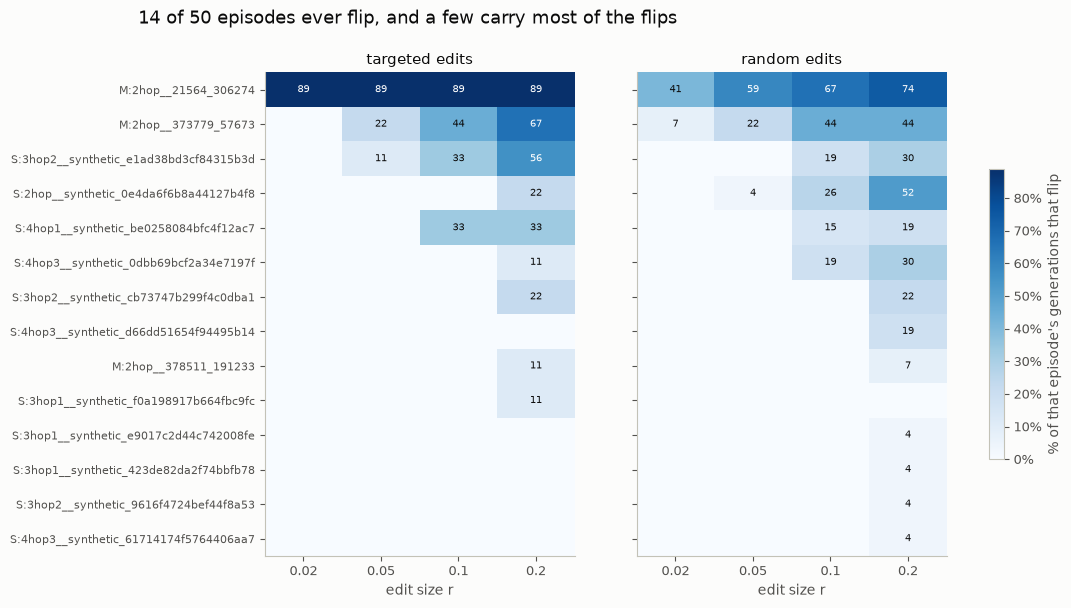

Top 3 episodes account for 70% of all flips (165 of 237).


In [7]:
per_ep = edits.groupby(["episode_id", "source", "edit_size"]).flip.mean().unstack(["source", "edit_size"]) * 100
per_ep = per_ep.loc[per_ep.sum(axis=1) > 0]
per_ep = per_ep.loc[per_ep.sum(axis=1).sort_values(ascending=False).index]
labels = [e.split("__natural")[0].replace("musique:", "M:").replace("synthetic:", "S:")[:38] for e in per_ep.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 0.32 * len(per_ep) + 1.8), sharey=True)
vmax = max(per_ep.max().max(), 1)
for ax, source in zip(axes, ["targeted", "random"]):
    m = per_ep[source][SIZES].to_numpy()
    im = ax.imshow(m, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(SIZES)), [f"{s:g}" for s in SIZES])
    ax.set_xlabel("edit size r")
    ax.set_title(f"{source} edits")
    ax.grid(False)
    for (r_, c_), v in np.ndenumerate(m):
        if v > 0:
            ax.text(c_, r_, f"{v:.0f}", ha="center", va="center", fontsize=7,
                    color="#ffffff" if v > vmax * 0.55 else INK)
axes[0].set_yticks(range(len(per_ep)), labels, fontsize=8)
fig.colorbar(im, ax=axes, shrink=0.6, label="% of that episode's generations that flip",
             format=mticker.PercentFormatter(decimals=0))
fig.suptitle(f"{len(per_ep)} of {edits.episode_id.nunique()} episodes ever flip, and a few carry most of the flips",
             x=0.01, ha="left", fontsize=13, color=INK)
plt.show()

total = edits.groupby("episode_id").flip.sum().sort_values(ascending=False)
print(f"Top 3 episodes account for {total.head(3).sum() / total.sum():.0%} of all flips "
      f"({int(total.head(3).sum())} of {int(total.sum())}).")

## 5. Why the effect is small: the model is very sure

Left: the baseline probability of the first answer token. Right: for each episode, that confidence against
how often an r = 0.2 edit changes its answer. Episodes near probability 1 barely move; the movers are the few
the model was unsure about.

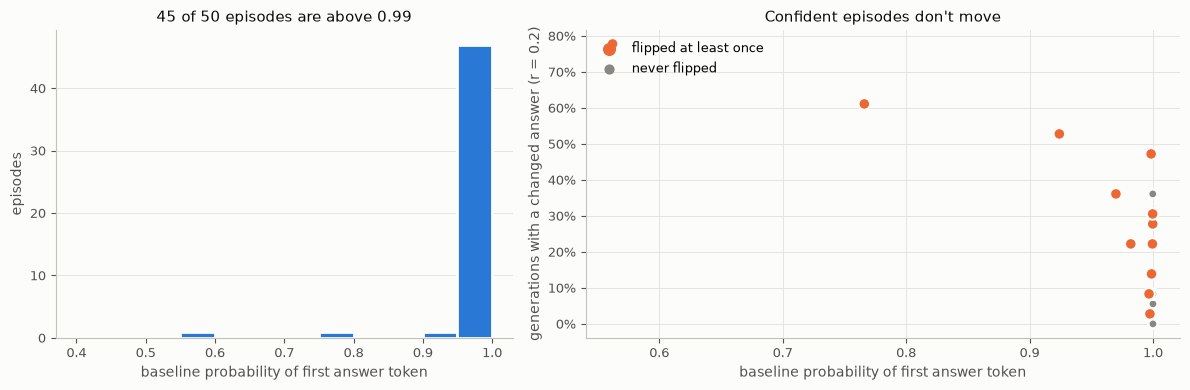

In [8]:
ep = edits[edits.edit_size == max(SIZES)].groupby("episode_id").agg(
    prob=("baseline_first_token_prob", "first"), changed=("answer_changed", "mean"), flipped=("flip", "mean"))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.3]})
bins = np.linspace(0.4, 1.0, 13)
a1.hist(base.first_token_logprob.pipe(np.exp), bins=bins, color=COLOR["L1 SAE"], edgecolor="#fcfcfb", linewidth=2)
a1.set_xlabel("baseline probability of first answer token")
a1.set_ylabel("episodes")
a1.set_title(f"{(np.exp(base.first_token_logprob) > 0.99).sum()} of {len(base)} episodes are above 0.99")

a2.scatter(ep.prob, ep.changed * 100, s=np.where(ep.flipped > 0, 70, 40),
           c=np.where(ep.flipped > 0, COLOR["Pretrained SAE"], RANDOM_GRAY),
           edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
a2.scatter([], [], s=70, c=COLOR["Pretrained SAE"], label="flipped at least once")
a2.scatter([], [], s=40, c=RANDOM_GRAY, label="never flipped")
a2.legend(loc="upper left")
a2.set_xlabel("baseline probability of first answer token")
a2.set_ylabel(f"generations with a changed answer (r = {max(SIZES):g})")
pct_axis(a2)
a2.grid(True, axis="both")
a2.set_title("Confident episodes don't move")
fig.tight_layout()
plt.show()

## 6. Are the targeted features even active at the edited token?

The number of edited features active at the edited token, for targeted edits (decrease and increase
arms edit 10 features; "both" edits 20). The L1 SAE's targeted features are mostly silent there,
so its "decrease" arm has almost nothing to decrease.

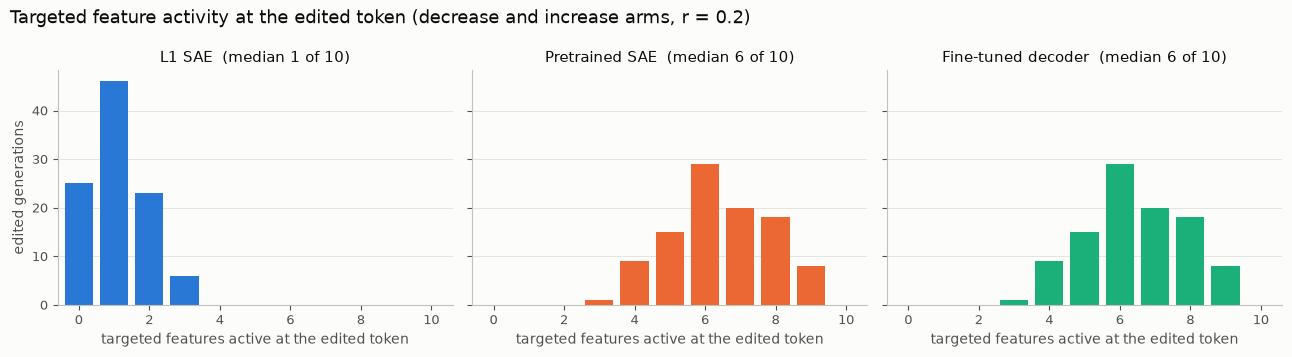

In [9]:
t = edits[(edits.source == "targeted") & (edits.edit_size == max(SIZES)) & (edits.arm != "both")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
top = int(t.edited_features_active.max())
for ax, rep in zip(axes, REPS):
    counts = t[t.representation == rep].edited_features_active.value_counts().reindex(range(top + 1), fill_value=0)
    ax.bar(counts.index, counts.values, width=0.8, color=COLOR[rep])
    ax.set_title(f"{rep}  (median {t[t.representation == rep].edited_features_active.median():.0f} of 10)")
    ax.set_xlabel("targeted features active at the edited token")
    ax.set_xlim(-0.6, 10.6)
axes[0].set_ylabel("edited generations")
fig.suptitle("Targeted feature activity at the edited token (decrease and increase arms, r = 0.2)",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout()
plt.show()

## 7. Answer quality: % out by r

"Out" answers (neither adoption nor retention) and degenerate answers are what larger edits risk.
The report's rule caps both at 5%. Degenerate answers are 0 everywhere, so only "out" is plotted.
Lines pool the three arms; single arms run higher (L1 SAE "both" reaches 6% at r = 0.2, see the table).
This is the headroom for trying a larger r.

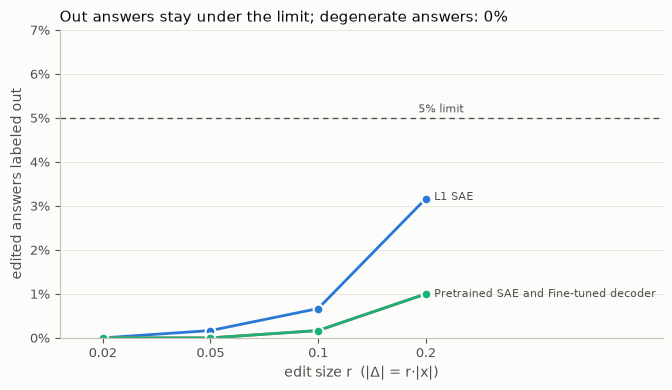

In [10]:
out = (edits.groupby(["representation", "edit_size"]).out.mean() * 100).rename("pct").reset_index()
fig, ax = plt.subplots(figsize=(7, 4))
ax.axhline(5, color=INK_2, linewidth=1, linestyle=(0, (4, 3)))
ax.annotate("5% limit", (len(SIZES) - 0.6, 5), xytext=(-4, 4), textcoords="offset points",
            ha="right", fontsize=8, color=INK_2)
ends = {}
for rep in REPS:
    s = out[out.representation == rep].sort_values("edit_size")
    ax.plot(range(len(s)), s.pct, "-o", color=COLOR[rep], markeredgecolor="#fcfcfb", markeredgewidth=1.5)
    ends.setdefault(round(s.pct.iloc[-1], 1), []).append(rep)   # equal endpoints share one label
for y, reps in ends.items():
    ax.annotate(" and ".join(reps), (len(SIZES) - 1, y), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK_2)
size_axis(ax)
ax.set_xlim(-0.4, len(SIZES) + 1.2)
pct_axis(ax)
ax.set_ylim(0, 7)
ax.set_ylabel("edited answers labeled out")
ax.set_title(f"Out answers stay under the limit; degenerate answers: {edits.degenerate.mean():.0%}",
             loc="left")
fig.tight_layout()
plt.show()

## Table view

The full choose-r report, for reading exact values.

In [11]:
report.drop(columns=['ci_lo', 'ci_hi'])

,Edit size r,Representation,Arm,N,Targeted flip %,Random flip %,Δ (pp),Δ 95% CI,% out,% degenerate,Meets suggested rule
0,0.02,L1 SAE,decrease,50,2.0,3.333333,-1.333333e+00,"[-4.0, +0.0]",0.0,0.0,False
1,0.02,L1 SAE,increase,50,0.0,0.000000,0.000000e+00,"[+0.0, +0.0]",0.0,0.0,False
2,0.02,L1 SAE,both,50,2.0,0.666667,1.333333e+00,"[+0.0, +4.0]",0.0,0.0,False
3,0.02,Pretrained SAE,decrease,50,2.0,0.666667,1.333333e+00,"[+0.0, +4.0]",0.0,0.0,False
4,0.02,Pretrained SAE,increase,50,2.0,0.666667,1.333333e+00,"[+0.0, +4.0]",0.0,0.0,False
5,0.02,Pretrained SAE,both,50,2.0,1.333333,6.666667e-01,"[+0.0, +2.0]",0.0,0.0,False
6,0.02,Fine-tuned decoder,decrease,50,2.0,0.666667,1.333333e+00,"[+0.0, +4.0]",0.0,0.0,False
7,0.02,Fine-tuned decoder,increase,50,2.0,0.666667,1.333333e+00,"[+0.0, +4.0]",0.0,0.0,False
8,0.02,Fine-tuned decoder,both,50,2.0,0.666667,1.333333e+00,"[+0.0, +4.0]",0.0,0.0,False
9,0.05,L1 SAE,decrease,50,6.0,4.000000,2.000000e+00,"[+0.0, +6.0]",0.0,0.0,False
